# Apple Equity Risk and Macroeconomic Context

**Grace Ngo | DATA 200, Dickinson College | original coursework Fall 2025**

How much downside accompanied Apple's historical price growth? This notebook runs the reviewed offline pipeline on the supplied snapshots. The benchmark uses prices on common dates and complete return months. Macro classifications are retrospective context, not tradable signals. See the README for definitions and limitations.


In [1]:
from pathlib import Path
import json
import sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'equity_review').is_dir()), None)
if root is None:
    raise RuntimeError('Open the notebook from the project directory.')
sys.path.insert(0, str(root))
from equity_review.analysis import build_analysis

report = build_analysis(root / 'data/snapshots', root / 'reports')
print('Complete Apple context:', report['analysis_start_month'], 'to', report['analysis_end_month'])
print('Benchmark baseline:', report['benchmark_base_date'], '| end:', report['benchmark_end_date'])
print('Benchmark return months:', report['benchmark_return_months'])


Complete Apple context: 2000-01 to 2024-12
Benchmark baseline: 2015-12-31 | end: 2024-12-31
Benchmark return months: 108


## Growth and downside on the same comparison window

Returns below exclude dividends. Month-end drawdown and down-market capture summarize different aspects of risk. The sample does not estimate risk-adjusted alpha or identify causes of outperformance.


In [2]:
for name in ['aapl_overlap', 'sp500_overlap']:
    print(name)
    for metric, value in report[name].items():
        print(f'  {metric}: {value}')
print('Geometric downside capture:', report['downside_capture_ratio'])
print('Down-market months:', report['down_market_months'])


aapl_overlap
  months: 108
  cumulative_price_return: 8.516245224652163
  annualized_geometric_price_return: 0.28445354814171697
  annualized_monthly_volatility: 0.28056309016572145
  worst_month: -0.18404458862727302
  negative_month_share: 0.4074074074074074
  maximum_month_end_drawdown: -0.30703333431648827
sp500_overlap
  months: 108
  cumulative_price_return: 1.8775942542344728
  annualized_geometric_price_return: 0.12461347838580261
  annualized_monthly_volatility: 0.1552903546354517
  worst_month: -0.12511932083595656
  negative_month_share: 0.3148148148148148
  maximum_month_end_drawdown: -0.2476952192321734
Geometric downside capture: 0.8522169279176166
Down-market months: 34


## Indexed prices and drawdowns

Baseline December 31, 2015; complete return months January 2016-December 2024. Monthly sampling omits intramonth extremes.


  classification                 regime  months  mean_monthly_price_return  median_monthly_price_return  negative_month_share  worst_monthly_price_return
       recession                      0     272                   0.027695                     0.029244              0.386029                   -0.577436
       recession                      1      28                   0.002454                     0.019823              0.500000                   -0.329558
inflation_regime            <4% CPI YoY     260                   0.028521                     0.029116              0.388462                   -0.577436
inflation_regime           >=4% CPI YoY      40                   0.004655                     0.034958              0.450000                   -0.329558
     rate_regime   Change within +/-1pp     191                   0.034749                     0.036670              0.350785                   -0.156070
     rate_regime Falling >=1pp over 12m      52                   0.013167  

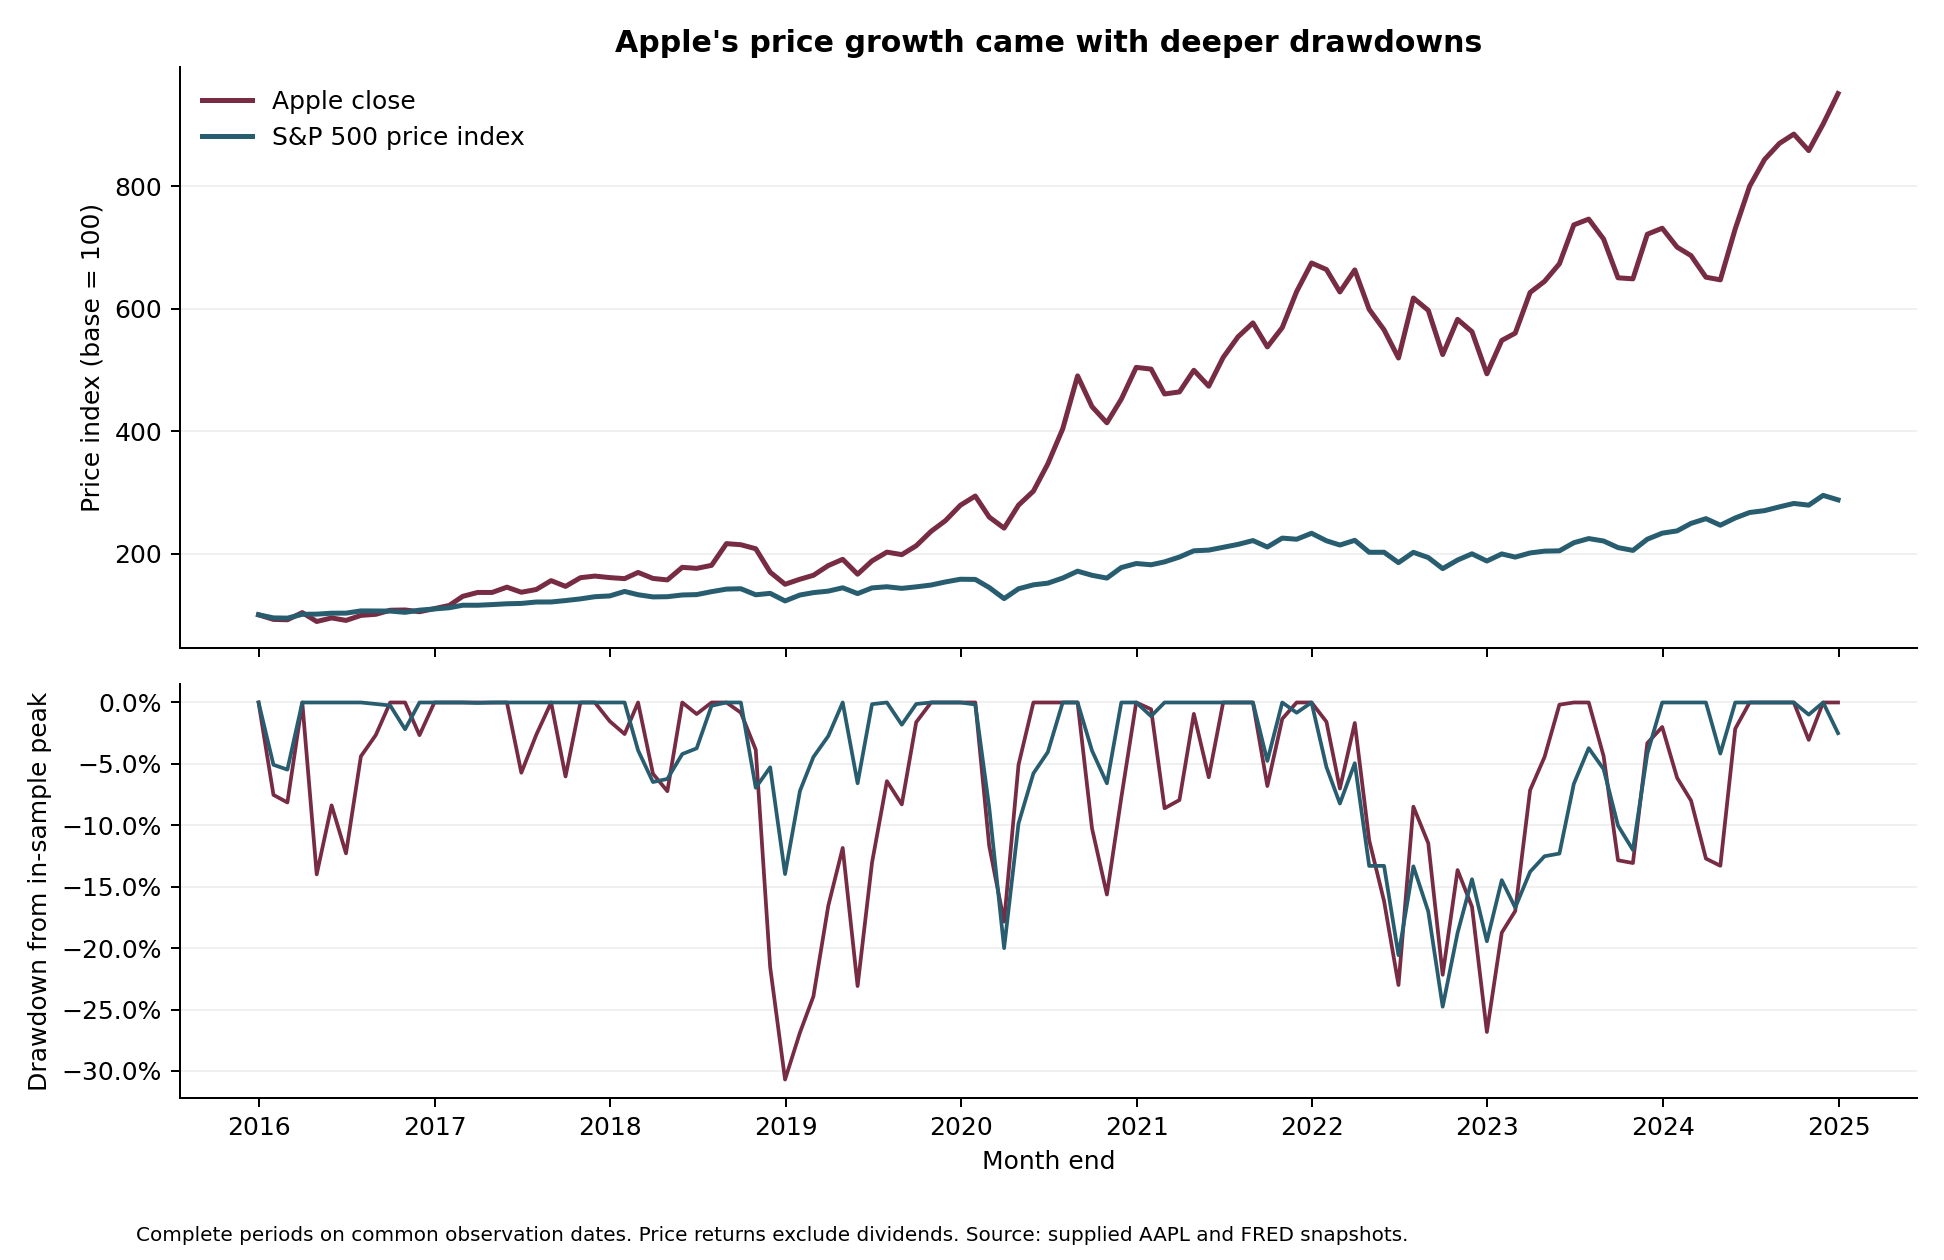

In [3]:
import pandas as pd
regimes = pd.read_csv(root / 'reports/regime_summary.csv')
print(regimes.to_string(index=False))


## Interpretation

The sample shows stronger Apple price growth with higher annualized volatility and a deeper maximum month-end drawdown. Its downside-capture ratio is below one in benchmark-negative months, illustrating why a single risk statistic is insufficient. Regime group means combine different eras and unequal sample sizes; the macro labels are not known at the observation date in the form used here. No policy effect, predictive performance or profitable timing rule is inferred.

The partial January 2025 is excluded. Input hashes, full tables and figures are written to `reports/`. Optional FRED retrieval uses an environment variable; the default run is offline.
